# نوت‌بوک ۰۵ — پیاده‌سازی و ارزیابی SVM خطی و غیرخطی

**پروژه:** Detecting Silent Failures of Uncertainty Estimators in Large Language Models under Distribution Shift

**هدف این نوت‌بوک:** اجرای دو طبقه‌بند SVM خطی و غیرخطی روی همان مسئله و همان ویژگی‌های نوت‌بوک ۰۴ و مقایسه خطای آن‌ها با NBC و BBN/TAN.

> **مرزبندی علمی:** این آزمایش، منبع دیتاست را بین `CommonsenseQA` و `ARC-Challenge` طبقه‌بندی می‌کند. این آزمایش به‌تنهایی تشخیص Silent Failure یا ارزیابی مستقیم عدم‌قطعیت LLM نیست؛ بلکه بخشی از تحلیل مقدماتی تفاوت دو دامنه و تکلیف درس شناسایی الگو است.

## ۱. طراحی آزمایش

- کلاس `0`: `CommonsenseQA`
- کلاس `1`: `ARC-Challenge`
- ویژگی‌ها:
  - `question_words`
  - `question_chars`
  - `avg_option_words`
- ویژگی `option_count` عمداً وارد مدل نمی‌شود تا طبقه‌بند صرفاً از تعداد گزینه‌ها برای تشخیص منبع داده استفاده نکند.
- تقسیم‌بندی اصلی `Train / Validation / Test` همان تقسیم‌بندی ذخیره‌شده در فایل داده است و تغییر نمی‌کند.
- برای هر دو SVM از `StandardScaler` استفاده می‌شود؛ scaler فقط روی Train برازش می‌شود.
- تنظیم پارامترها فقط با Validation انجام می‌شود.
- پس از انتخاب پارامترها، مدل نهایی روی `Train + Validation` آموزش داده و فقط یک‌بار روی Test ارزیابی می‌شود.
- برای مقابله با نامتوازن بودن کلاس‌ها در Train، از `class_weight="balanced"` استفاده می‌شود.

**مدل‌ها:**
1. `SVM Linear`: پیاده‌سازی خطی با `LinearSVC`
2. `SVM RBF`: پیاده‌سازی غیرخطی با کرنل Radial Basis Function

In [1]:
from pathlib import Path
import io
import os
import json
import zipfile
import urllib.request
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.svm import LinearSVC, SVC
from sklearn.metrics import (
    accuracy_score,
    balanced_accuracy_score,
    precision_recall_fscore_support,
    confusion_matrix,
    ConfusionMatrixDisplay,
    classification_report,
)

RANDOM_STATE = 42

FEATURES = [
    "question_words",
    "question_chars",
    "avg_option_words",
]

CLASS_NAMES = {
    0: "CommonsenseQA",
    1: "ARC-Challenge",
}

LINEAR_C_VALUES = [0.01, 0.1, 1, 10, 100]
RBF_C_VALUES = [0.1, 1, 10, 100]
RBF_GAMMA_VALUES = ["scale", 0.01, 0.1, 1]

print("کتابخانه‌ها با موفقیت بارگذاری شدند.")
print("ویژگی‌ها:", FEATURES)

try:
    import google.colab
    IN_COLAB = True
except ImportError:
    IN_COLAB = False

print("Google Colab:", IN_COLAB)

کتابخانه‌ها با موفقیت بارگذاری شدند.
ویژگی‌ها: ['question_words', 'question_chars', 'avg_option_words']
Google Colab: False


## ۲. بارگذاری داده‌های پروژه

ورودی این نوت‌بوک همان فایل `outputs/numeric_features.csv` تولیدشده در نوت‌بوک ۰۱ است.

اگر فایل در محیط اجرا پیدا نشود، کد ابتدا مخزن GitHub پروژه را در صورت امکان دریافت می‌کند و سپس بارگذاری را دوباره امتحان می‌کند. در صورت اجرا در محیط محلی، می‌توان فایل `numeric_features.csv` را در پوشه `outputs` پروژه قرار داد.

In [2]:
REPO_NAME = "Detecting-Silent-Failures-of-Uncertainty-Estimators"
REPO_URL = (
    "https://github.com/mmnsrti/"
    "Detecting-Silent-Failures-of-Uncertainty-Estimators"
)
RAW_CSV_URL = (
    "https://raw.githubusercontent.com/mmnsrti/"
    "Detecting-Silent-Failures-of-Uncertainty-Estimators/main/"
    "outputs/numeric_features.csv"
)

def candidate_project_roots():
    candidates = [
        Path.cwd(),
        Path.cwd().parent,
        Path("/content"),
        Path("/content") / REPO_NAME,
        Path("/content/drive/MyDrive") / REPO_NAME,
    ]

    roots = []
    seen = set()

    for base in candidates:
        if not base.exists():
            continue

        possible = [base]
        try:
            possible.extend([p for p in base.iterdir() if p.is_dir()])
        except (PermissionError, OSError):
            pass

        for path in possible:
            try:
                key = str(path.resolve())
            except OSError:
                key = str(path)
            if key not in seen:
                seen.add(key)
                roots.append(path)

    return roots


def find_csv_in_roots():
    for root in candidate_project_roots():
        for csv_path in [
            root / "outputs" / "numeric_features.csv",
            root / "numeric_features.csv",
        ]:
            if csv_path.exists() and csv_path.stat().st_size > 0:
                return pd.read_csv(csv_path), root, str(csv_path)

        for zip_path in [
            root / "outputs.zip",
            root / "outputs" / "outputs.zip",
        ]:
            if zip_path.exists():
                try:
                    with zipfile.ZipFile(zip_path, "r") as zf:
                        candidates = [
                            name for name in zf.namelist()
                            if name.endswith("numeric_features.csv")
                        ]
                        if candidates:
                            member = candidates[0]
                            data = pd.read_csv(io.BytesIO(zf.read(member)))
                            return data, root, f"{zip_path} -> {member}"
                except (zipfile.BadZipFile, OSError):
                    pass

    return None, None, None


df_raw, PROJECT_ROOT, DATA_SOURCE = find_csv_in_roots()

if df_raw is None:
    repo_dir = Path("/content") / REPO_NAME if IN_COLAB else None

    if IN_COLAB and repo_dir is not None and not repo_dir.exists():
        import subprocess
        print("در حال دریافت مخزن GitHub پروژه...")
        try:
            subprocess.run(
                ["git", "clone", REPO_URL + ".git", str(repo_dir)],
                check=False
            )
            df_raw, PROJECT_ROOT, DATA_SOURCE = find_csv_in_roots()
        except Exception as clone_err:
            print("خطا در git clone:", clone_err)

if df_raw is None:
    print("فایل محلی پیدا نشد؛ تلاش برای دریافت numeric_features.csv از GitHub...")
    try:
        request = urllib.request.Request(
            RAW_CSV_URL,
            headers={"User-Agent": "Mozilla/5.0"}
        )
        with urllib.request.urlopen(request, timeout=30) as response:
            csv_bytes = response.read()

        df_raw = pd.read_csv(io.BytesIO(csv_bytes))
        PROJECT_ROOT = Path.cwd()
        save_path = PROJECT_ROOT / "outputs" / "numeric_features.csv"
        save_path.parent.mkdir(parents=True, exist_ok=True)
        save_path.write_bytes(csv_bytes)
        DATA_SOURCE = RAW_CSV_URL

    except Exception as download_error:
        print("دریافت خودکار موفق نبود:", download_error)

        if IN_COLAB:
            from google.colab import files
            print(
                "لطفاً فایل numeric_features.csv یا outputs.zip را "
                "از رایانه خود انتخاب و آپلود کن."
            )
            uploaded = files.upload()

            if not uploaded:
                raise FileNotFoundError("هیچ فایلی آپلود نشد.")

            selected_name, selected_bytes = next(iter(uploaded.items()))
            PROJECT_ROOT = Path.cwd()

            if selected_name.lower().endswith(".csv"):
                df_raw = pd.read_csv(io.BytesIO(selected_bytes))
                save_path = PROJECT_ROOT / "outputs" / "numeric_features.csv"
                save_path.parent.mkdir(parents=True, exist_ok=True)
                save_path.write_bytes(selected_bytes)
                DATA_SOURCE = f"Manual upload: {selected_name}"

            elif selected_name.lower().endswith(".zip"):
                with zipfile.ZipFile(io.BytesIO(selected_bytes), "r") as zf:
                    matches = [
                        name for name in zf.namelist()
                        if name.endswith("numeric_features.csv")
                    ]
                    if not matches:
                        raise FileNotFoundError(
                            "در فایل ZIP، numeric_features.csv پیدا نشد."
                        )
                    member = matches[0]
                    csv_bytes = zf.read(member)
                    df_raw = pd.read_csv(io.BytesIO(csv_bytes))
                    save_path = PROJECT_ROOT / "outputs" / "numeric_features.csv"
                    save_path.parent.mkdir(parents=True, exist_ok=True)
                    save_path.write_bytes(csv_bytes)
                    DATA_SOURCE = f"Manual upload: {selected_name} -> {member}"

            else:
                raise ValueError(
                    "فرمت فایل پشتیبانی نمی‌شود؛ CSV یا ZIP آپلود کن."
                )
        else:
            raise FileNotFoundError(
                "numeric_features.csv پیدا نشد. فایل را در outputs قرار بده "
                "یا اتصال اینترنت برای دریافت از GitHub را بررسی کن."
            )

print("منبع داده:", DATA_SOURCE)
print("ابعاد داده خام:", df_raw.shape)
print("ستون‌ها:", df_raw.columns.tolist())

OUTPUT_DIR = Path(PROJECT_ROOT) / "outputs" / "svm_classification"
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
print("مسیر ذخیره خروجی‌ها:", OUTPUT_DIR)


منبع داده: D:\app\ai\Detecting Silent Failures of Uncertainty Estimators\outputs\numeric_features.csv
ابعاد داده خام: (14692, 8)
ستون‌ها: ['dataset', 'split', 'source_file', 'source_row', 'question_words', 'question_chars', 'avg_option_words', 'option_count']
مسیر ذخیره خروجی‌ها: D:\app\ai\Detecting Silent Failures of Uncertainty Estimators\outputs\svm_classification


## ۳. پاک‌سازی و آماده‌سازی برچسب‌ها

نام دیتاست‌ها و splitها یکدست می‌شوند. ردیف‌هایی که برچسب یا یکی از سه ویژگی موردنیازشان نامعتبر یا مفقود باشد، مانند منطق نوت‌بوک ۰۴ از تحلیل حذف می‌شوند. مقادیر بی‌نهایت نیز به‌عنوان مقدار نامعتبر در نظر گرفته می‌شوند.

In [3]:
required_columns = {
    "dataset",
    "split",
    "question_words",
    "question_chars",
    "avg_option_words",
}

missing_columns = required_columns - set(df_raw.columns)
if missing_columns:
    raise ValueError(
        f"ستون‌های لازم در فایل وجود ندارند: {sorted(missing_columns)}"
    )


def normalize_dataset(value):
    s = str(value).strip().lower().replace("_", "").replace("-", "").replace(" ", "")
    if "commonsenseqa" in s or s == "csqa":
        return "CommonsenseQA"
    if "arc" in s:
        return "ARC-Challenge"
    return np.nan


def normalize_split(value):
    s = str(value).strip().lower()
    mapping = {
        "train": "train",
        "training": "train",
        "validation": "validation",
        "valid": "validation",
        "val": "validation",
        "dev": "validation",
        "test": "test",
    }
    return mapping.get(s, np.nan)


df = df_raw.copy()
df["dataset"] = df["dataset"].map(normalize_dataset)
df["split"] = df["split"].map(normalize_split)

for feature in FEATURES:
    df[feature] = pd.to_numeric(df[feature], errors="coerce")
    df[feature] = df[feature].replace([np.inf, -np.inf], np.nan)

before_cleaning = len(df)
df = df.dropna(subset=["dataset", "split"] + FEATURES).copy()
removed_rows = before_cleaning - len(df)

df["y"] = df["dataset"].map({
    "CommonsenseQA": 0,
    "ARC-Challenge": 1,
}).astype(int)

df = df[df["split"].isin(["train", "validation", "test"])].copy()

if df.empty:
    raise ValueError("پس از پاک‌سازی هیچ نمونه معتبری باقی نمانده است.")

print(f"تعداد ردیف‌های اولیه: {before_cleaning:,}")
print(f"تعداد ردیف‌های حذف‌شده: {removed_rows:,}")
print(f"تعداد ردیف‌های معتبر: {len(df):,}")

split_summary = (
    df.groupby(["split", "dataset"])
      .size()
      .unstack(fill_value=0)
      .reindex(index=["train", "validation", "test"], fill_value=0)
)
display(split_summary)

train_df = df[df["split"] == "train"].copy()
val_df = df[df["split"] == "validation"].copy()
test_df = df[df["split"] == "test"].copy()

for split_name, part in [
    ("Train", train_df),
    ("Validation", val_df),
    ("Test", test_df),
]:
    if part.empty or set(part["y"].unique()) != {0, 1}:
        raise ValueError(
            f"هر دو کلاس باید در split مربوط به {split_name} حضور داشته باشند."
        )

print("\nتعداد نمونه‌ها:")
print("Train:", len(train_df))
print("Validation:", len(val_df))
print("Test:", len(test_df))

تعداد ردیف‌های اولیه: 14,692
تعداد ردیف‌های حذف‌شده: 0
تعداد ردیف‌های معتبر: 14,692


dataset,ARC-Challenge,CommonsenseQA
split,,
train,1119,9741
validation,299,1221
test,1172,1140



تعداد نمونه‌ها:
Train: 10860
Validation: 1520
Test: 2312


## ۴. تعریف معیارهای ارزیابی و جست‌وجوی پارامترها

پارامترهای مدل فقط با داده‌های Validation انتخاب می‌شوند.

- معیار اصلی انتخاب: `Macro F1`
- معیار دوم برای شکستن تساوی: `Balanced Accuracy`
- در صورت تساوی هر دو معیار، Accuracy نیز برای مرتب‌سازی استفاده می‌شود.

در مدل خطی، پارامتر `C` کنترل‌کننده میزان regularization است. در مدل RBF علاوه بر `C`، پارامتر `gamma` نیز تنظیم می‌شود.

In [4]:
def calculate_metrics(y_true, y_pred):
    precision_macro, recall_macro, f1_macro, _ = (
        precision_recall_fscore_support(
            y_true,
            y_pred,
            average="macro",
            zero_division=0,
        )
    )

    return {
        "accuracy": accuracy_score(y_true, y_pred),
        "error_rate": 1 - accuracy_score(y_true, y_pred),
        "balanced_accuracy": balanced_accuracy_score(y_true, y_pred),
        "macro_precision": precision_macro,
        "macro_recall": recall_macro,
        "macro_f1": f1_macro,
    }


def build_linear_svm(C):
    return Pipeline([
        ("scaler", StandardScaler()),
        ("svm", LinearSVC(
            C=float(C),
            class_weight="balanced",
            dual=False,
            max_iter=50000,
            random_state=RANDOM_STATE,
        )),
    ])


def build_rbf_svm(C, gamma):
    return Pipeline([
        ("scaler", StandardScaler()),
        ("svm", SVC(
            kernel="rbf",
            C=float(C),
            gamma=gamma,
            class_weight="balanced",
            cache_size=1000,
        )),
    ])


X_train = train_df[FEATURES]
y_train = train_df["y"].to_numpy()

X_val = val_df[FEATURES]
y_val = val_df["y"].to_numpy()


def run_validation_search(model_name, candidates):
    rows = []
    fitted_candidates = []

    for params in candidates:
        if model_name == "SVM Linear":
            model = build_linear_svm(params["C"])
        elif model_name == "SVM RBF":
            model = build_rbf_svm(params["C"], params["gamma"])
        else:
            raise ValueError("نام مدل ناشناخته است.")

        with warnings.catch_warnings(record=True) as caught:
            warnings.simplefilter("always")
            model.fit(X_train, y_train)

        val_predictions = model.predict(X_val)
        metrics = calculate_metrics(y_val, val_predictions)

        row = {
            "model": model_name,
            **params,
            **metrics,
            "convergence_warning": any(
                "converg" in str(w.message).lower() for w in caught
            ),
        }
        rows.append(row)
        fitted_candidates.append((row, model))

        print(
            f"{model_name} | params={params} | "
            f"Macro F1={metrics['macro_f1']:.4f} | "
            f"Balanced Acc={metrics['balanced_accuracy']:.4f}"
        )

    results = pd.DataFrame(rows).sort_values(
        ["macro_f1", "balanced_accuracy", "accuracy"],
        ascending=[False, False, False],
    ).reset_index(drop=True)

    best_row = results.iloc[0].to_dict()

    best_model = None
    for row, model in fitted_candidates:
        if all(row.get(k) == best_row.get(k) for k in params.keys()):
            # The parameter keys are the same for all candidates of this model.
            best_model = model
            break

    return results, best_row, best_model

## ۵. تنظیم SVM خطی با Validation

برای مدل خطی، چند مقدار `C` بررسی می‌شود. در این مرحله Test استفاده نمی‌شود.

In [5]:
linear_candidates = [
    {"C": c}
    for c in LINEAR_C_VALUES
]

linear_validation_results, best_linear_row, best_linear_validation_model = (
    run_validation_search("SVM Linear", linear_candidates)
)

display(linear_validation_results.round(4))

linear_validation_results.to_csv(
    OUTPUT_DIR / "svm_linear_validation_search.csv",
    index=False,
)

BEST_LINEAR_C = float(best_linear_row["C"])
print("بهترین C برای SVM خطی:", BEST_LINEAR_C)

SVM Linear | params={'C': 0.01} | Macro F1=0.9011 | Balanced Acc=0.8844


SVM Linear | params={'C': 0.1} | Macro F1=0.8997 | Balanced Acc=0.8862
SVM Linear | params={'C': 1} | Macro F1=0.8997 | Balanced Acc=0.8862
SVM Linear | params={'C': 10} | Macro F1=0.8988 | Balanced Acc=0.8857
SVM Linear | params={'C': 100} | Macro F1=0.8988 | Balanced Acc=0.8857


,model,C,accuracy,error_rate,balanced_accuracy,macro_precision,macro_recall,macro_f1,convergence_warning
0,SVM Linear,0.01,0.9401,0.0599,0.8844,0.9208,0.8844,0.9011,False
1,SVM Linear,0.10,0.9388,0.0612,0.8862,0.9153,0.8862,0.8997,False
2,SVM Linear,1.00,0.9388,0.0612,0.8862,0.9153,0.8862,0.8997,False
3,SVM Linear,10.00,0.9382,0.0618,0.8857,0.9137,0.8857,0.8988,False
4,SVM Linear,100.00,0.9382,0.0618,0.8857,0.9137,0.8857,0.8988,False


بهترین C برای SVM خطی: 0.01


## ۶. تنظیم SVM غیرخطی با کرنل RBF

در این مدل، ترکیب‌های مختلف `C` و `gamma` بررسی می‌شوند. انتخاب نهایی فقط بر اساس نتایج Validation انجام می‌شود.

In [6]:
rbf_candidates = [
    {"C": c, "gamma": gamma}
    for c in RBF_C_VALUES
    for gamma in RBF_GAMMA_VALUES
]

rbf_validation_results, best_rbf_row, best_rbf_validation_model = (
    run_validation_search("SVM RBF", rbf_candidates)
)

display(rbf_validation_results.round(4))

rbf_validation_results.to_csv(
    OUTPUT_DIR / "svm_rbf_validation_search.csv",
    index=False,
)

BEST_RBF_C = float(best_rbf_row["C"])
BEST_RBF_GAMMA = best_rbf_row["gamma"]

print("بهترین C برای SVM RBF:", BEST_RBF_C)
print("بهترین gamma برای SVM RBF:", BEST_RBF_GAMMA)

SVM RBF | params={'C': 0.1, 'gamma': 'scale'} | Macro F1=0.8968 | Balanced Acc=0.8769


SVM RBF | params={'C': 0.1, 'gamma': 0.01} | Macro F1=0.8929 | Balanced Acc=0.8605


SVM RBF | params={'C': 0.1, 'gamma': 0.1} | Macro F1=0.8932 | Balanced Acc=0.8651


SVM RBF | params={'C': 0.1, 'gamma': 1} | Macro F1=0.8958 | Balanced Acc=0.8799


SVM RBF | params={'C': 1, 'gamma': 'scale'} | Macro F1=0.8977 | Balanced Acc=0.8807


SVM RBF | params={'C': 1, 'gamma': 0.01} | Macro F1=0.8970 | Balanced Acc=0.8701


... (8 outputs left out)

SVM RBF | params={'C': 100, 'gamma': 0.1} | Macro F1=0.9054 | Balanced Acc=0.8840


SVM RBF | params={'C': 100, 'gamma': 1} | Macro F1=0.9056 | Balanced Acc=0.8852


,model,C,gamma,accuracy,error_rate,balanced_accuracy,macro_precision,macro_recall,macro_f1,convergence_warning
0,SVM RBF,10.0,1,0.9447,0.0553,0.8848,0.9355,0.8848,0.9073,False
1,SVM RBF,100.0,scale,0.9441,0.0559,0.8856,0.9324,0.8856,0.9066,False
2,SVM RBF,10.0,0.1,0.9441,0.0559,0.8844,0.9337,0.8844,0.9063,False
3,SVM RBF,100.0,1,0.9434,0.0566,0.8852,0.9306,0.8852,0.9056,False
4,SVM RBF,100.0,0.01,0.9441,0.0559,0.8806,0.9376,0.8806,0.9055,False
5,SVM RBF,100.0,0.1,0.9434,0.0566,0.8840,0.9319,0.8840,0.9054,False
6,SVM RBF,1.0,1,0.9428,0.0572,0.8836,0.9301,0.8836,0.9044,False
7,SVM RBF,1.0,0.1,0.9421,0.0579,0.8806,0.9308,0.8806,0.9029,False
8,SVM RBF,10.0,scale,0.9414,0.0586,0.8827,0.9265,0.8827,0.9025,False
9,SVM RBF,1.0,scale,0.9382,0.0618,0.8807,0.9179,0.8807,0.8977,False


بهترین C برای SVM RBF: 10.0
بهترین gamma برای SVM RBF: 1


## ۷. آموزش نهایی و ارزیابی روی Test

پس از انتخاب پارامترها، هر دو مدل از ابتدا روی ترکیب `Train + Validation` آموزش داده می‌شوند. سپس Test برای ارزیابی نهایی استفاده می‌شود.

**نکته جلوگیری از نشت اطلاعات:** scaler نهایی نیز فقط روی `Train + Validation` برازش می‌شود؛ هیچ آماری از Test برای آموزش یا تنظیم پارامترها استفاده نمی‌شود.

In [7]:
train_validation_df = pd.concat(
    [train_df, val_df],
    axis=0,
    ignore_index=True,
)

X_trainval = train_validation_df[FEATURES]
y_trainval = train_validation_df["y"].to_numpy()

X_test = test_df[FEATURES]
y_test = test_df["y"].to_numpy()

final_linear_svm = build_linear_svm(BEST_LINEAR_C)
final_rbf_svm = build_rbf_svm(BEST_RBF_C, BEST_RBF_GAMMA)

final_linear_svm.fit(X_trainval, y_trainval)
final_rbf_svm.fit(X_trainval, y_trainval)

linear_test_pred = final_linear_svm.predict(X_test)
rbf_test_pred = final_rbf_svm.predict(X_test)

linear_test_metrics = calculate_metrics(y_test, linear_test_pred)
rbf_test_metrics = calculate_metrics(y_test, rbf_test_pred)

svm_test_metrics = pd.DataFrame([
    {"model": "SVM Linear", **linear_test_metrics},
    {"model": "SVM RBF", **rbf_test_metrics},
])

display(svm_test_metrics.round(4))

svm_test_metrics.to_csv(
    OUTPUT_DIR / "svm_test_metrics.csv",
    index=False,
)

,model,accuracy,error_rate,balanced_accuracy,macro_precision,macro_recall,macro_f1
0,SVM Linear,0.8927,0.1073,0.8938,0.9012,0.8938,0.8923
1,SVM RBF,0.8906,0.1094,0.8917,0.9013,0.8917,0.8900


## ۸. Confusion Matrix و گزارش عملکرد هر کلاس

در ماتریس‌های زیر، سطرها کلاس واقعی و ستون‌ها کلاس پیش‌بینی‌شده هستند.

خطای هر کلاس از رابطه زیر محاسبه می‌شود:

\[
Error_c = 1 - Recall_c
\]

بنابراین خطای کلاس، نسبت نمونه‌های همان کلاس است که به‌اشتباه به کلاس دیگر نسبت داده شده‌اند.

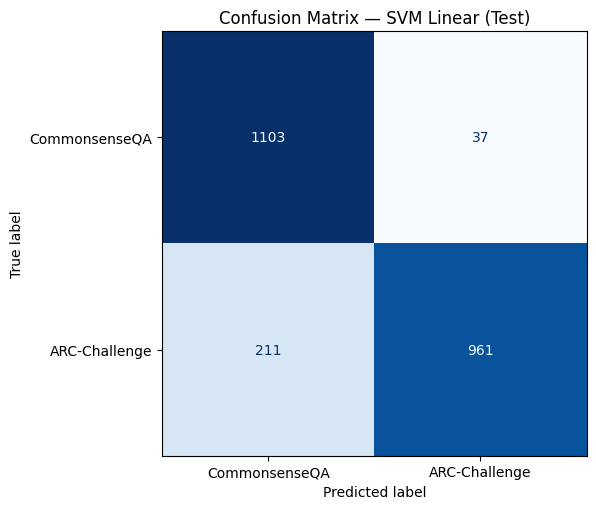

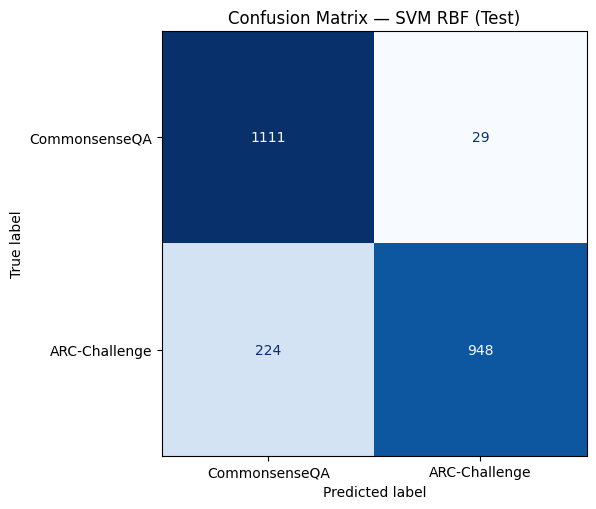

,model,class,precision,recall,f1,class_error_rate,support
0,SVM Linear,CommonsenseQA,0.8394,0.9675,0.8989,0.0325,1140
1,SVM Linear,ARC-Challenge,0.9629,0.8200,0.8857,0.1800,1172
2,SVM RBF,CommonsenseQA,0.8322,0.9746,0.8978,0.0254,1140
3,SVM RBF,ARC-Challenge,0.9703,0.8089,0.8823,0.1911,1172


In [8]:
def save_confusion_matrix(y_true, y_pred, model_name, file_stem):
    cm = confusion_matrix(y_true, y_pred, labels=[0, 1])

    fig, ax = plt.subplots(figsize=(6.2, 5.2))
    display_cm = ConfusionMatrixDisplay(
        confusion_matrix=cm,
        display_labels=[
            CLASS_NAMES[0],
            CLASS_NAMES[1],
        ],
    )
    display_cm.plot(
        ax=ax,
        cmap="Blues",
        values_format="d",
        colorbar=False,
    )
    ax.set_title(f"Confusion Matrix — {model_name} (Test)")
    fig.tight_layout()
    fig.savefig(
        OUTPUT_DIR / f"{file_stem}_confusion_matrix.png",
        dpi=180,
        bbox_inches="tight",
    )
    plt.show()

    cm_df = pd.DataFrame(
        cm,
        index=["Actual_CSQA", "Actual_ARC"],
        columns=["Predicted_CSQA", "Predicted_ARC"],
    )
    cm_df.to_csv(
        OUTPUT_DIR / f"{file_stem}_confusion_matrix.csv"
    )
    return cm_df


cm_linear = save_confusion_matrix(
    y_test,
    linear_test_pred,
    "SVM Linear",
    "svm_linear",
)

cm_rbf = save_confusion_matrix(
    y_test,
    rbf_test_pred,
    "SVM RBF",
    "svm_rbf",
)


def make_class_report(y_true, y_pred, model_name, file_stem):
    report_dict = classification_report(
        y_true,
        y_pred,
        labels=[0, 1],
        target_names=[
            CLASS_NAMES[0],
            CLASS_NAMES[1],
        ],
        output_dict=True,
        zero_division=0,
    )

    report_df = pd.DataFrame(report_dict).transpose()
    report_df.to_csv(
        OUTPUT_DIR / f"{file_stem}_classification_report.csv"
    )

    class_rows = []
    for class_name in [CLASS_NAMES[0], CLASS_NAMES[1]]:
        values = report_dict[class_name]
        class_rows.append({
            "model": model_name,
            "class": class_name,
            "precision": values["precision"],
            "recall": values["recall"],
            "f1": values["f1-score"],
            "class_error_rate": 1 - values["recall"],
            "support": int(values["support"]),
        })

    return report_df, pd.DataFrame(class_rows)


linear_report, linear_class_metrics = make_class_report(
    y_test,
    linear_test_pred,
    "SVM Linear",
    "svm_linear",
)

rbf_report, rbf_class_metrics = make_class_report(
    y_test,
    rbf_test_pred,
    "SVM RBF",
    "svm_rbf",
)

svm_class_metrics = pd.concat(
    [linear_class_metrics, rbf_class_metrics],
    ignore_index=True,
)

display(svm_class_metrics.round(4))

svm_class_metrics.to_csv(
    OUTPUT_DIR / "svm_per_class_metrics.csv",
    index=False,
)

## ۹. مقایسه SVM با NBC و BBN/TAN

نتایج NBC و BBN/TAN از اجرای قبلی نوت‌بوک ۰۴ و فایل خروجی `classification_v3.zip` ثبت شده‌اند. این مقادیر دوباره در این نوت‌بوک آموزش داده نمی‌شوند؛ صرفاً برای مقایسه با SVM در همان آزمایش و همان Test به جدول اضافه می‌شوند.

**کنترل مقایسه:** تعداد نمونه‌های Test باید با اجرای قبلی برابر باشد: ۱۱۴۰ نمونه CommonsenseQA و ۱۱۷۲ نمونه ARC-Challenge. این کنترل، سازگاری تعداد نمونه‌ها را می‌سنجد؛ برای مقایسه دقیق، فایل داده و تعریف splitها نیز باید همان نسخه قبلی باشند.

In [9]:
# معیارهای واقعی ثبت‌شده در خروجی اجرای قبلی نوت‌بوک ۰۴.
# این اعداد از classification_v3.zip خوانده شده‌اند.
PREVIOUS_BASELINES = pd.DataFrame([
    {
        "model": "BBN/TAN",
        "accuracy": 0.7768166089965398,
        "error_rate": 1 - 0.7768166089965398,
        "balanced_accuracy": 0.7777079216813364,
        "macro_precision": 0.7817876932050161,
        "macro_recall": 0.7777079216813364,
        "macro_f1": 0.7761727650147243,
        "class_error_CSQA": 1 - 0.8421052631578947,
        "class_error_ARC": 1 - 0.7133105802047781,
        "source": "Notebook 04 — classification_v3.zip",
    },
    {
        "model": "NBC",
        "accuracy": 0.726643598615917,
        "error_rate": 1 - 0.726643598615917,
        "balanced_accuracy": 0.7274893718938986,
        "macro_precision": 0.7305435458668973,
        "macro_recall": 0.7274893718938986,
        "macro_f1": 0.7259296772717212,
        "class_error_CSQA": 1 - 0.7885964912280702,
        "class_error_ARC": 1 - 0.6663822525597269,
        "source": "Notebook 04 — classification_v3.zip",
    },
])

test_counts = test_df["y"].value_counts().to_dict()
expected_test_counts = {0: 1140, 1: 1172}
same_test_counts = (
    test_counts.get(0, 0) == expected_test_counts[0]
    and test_counts.get(1, 0) == expected_test_counts[1]
)

print("تعداد Test فعلی:", test_counts)
print("تعداد Test اجرای قبلی:", expected_test_counts)

if same_test_counts:
    print(
        "کنترل تعداد نمونه‌های Test موفق بود. "
        "مقایسه با نتایج قبلی نمایش داده می‌شود."
    )
else:
    print(
        "هشدار: تعداد نمونه‌های Test با اجرای قبلی یکسان نیست. "
        "نتایج NBC و BBN/TAN برای مقایسه مستقیم در جدول نهایی وارد نمی‌شوند."
    )

svm_comparison = svm_test_metrics.copy()
svm_comparison["class_error_CSQA"] = [
    linear_class_metrics.loc[
        linear_class_metrics["class"] == "CommonsenseQA",
        "class_error_rate"
    ].iloc[0],
    rbf_class_metrics.loc[
        rbf_class_metrics["class"] == "CommonsenseQA",
        "class_error_rate"
    ].iloc[0],
]
svm_comparison["class_error_ARC"] = [
    linear_class_metrics.loc[
        linear_class_metrics["class"] == "ARC-Challenge",
        "class_error_rate"
    ].iloc[0],
    rbf_class_metrics.loc[
        rbf_class_metrics["class"] == "ARC-Challenge",
        "class_error_rate"
    ].iloc[0],
]
svm_comparison["source"] = "Current Notebook 05 — Test"

if same_test_counts:
    comparison_df = pd.concat(
        [PREVIOUS_BASELINES, svm_comparison],
        ignore_index=True,
        sort=False,
    )
else:
    comparison_df = svm_comparison.copy()

comparison_columns = [
    "model",
    "accuracy",
    "error_rate",
    "balanced_accuracy",
    "macro_precision",
    "macro_recall",
    "macro_f1",
    "class_error_CSQA",
    "class_error_ARC",
    "source",
]

if "error_rate" not in comparison_df.columns or comparison_df["error_rate"].isna().any():
    comparison_df["error_rate"] = comparison_df["error_rate"].fillna(1 - comparison_df["accuracy"])

comparison_df = comparison_df[comparison_columns]
display(comparison_df.round(4))

comparison_df.to_csv(
    OUTPUT_DIR / "classifier_comparison_test.csv",
    index=False,
)


تعداد Test فعلی: {1: 1172, 0: 1140}
تعداد Test اجرای قبلی: {0: 1140, 1: 1172}
کنترل تعداد نمونه‌های Test موفق بود. مقایسه با نتایج قبلی نمایش داده می‌شود.


,model,accuracy,error_rate,balanced_accuracy,macro_precision,macro_recall,macro_f1,class_error_CSQA,class_error_ARC,source
0,BBN/TAN,0.7768,0.2232,0.7777,0.7818,0.7777,0.7762,0.1579,0.2867,Notebook 04 — classification_v3.zip
1,NBC,0.7266,0.2734,0.7275,0.7305,0.7275,0.7259,0.2114,0.3336,Notebook 04 — classification_v3.zip
2,SVM Linear,0.8927,0.1073,0.8938,0.9012,0.8938,0.8923,0.0325,0.1800,Current Notebook 05 — Test
3,SVM RBF,0.8906,0.1094,0.8917,0.9013,0.8917,0.8900,0.0254,0.1911,Current Notebook 05 — Test


## ۱۰. نمودار مقایسه خطا و Macro F1

نمودارها بر اساس نتایج Test رسم می‌شوند. اگر تعداد نمونه‌های Test با اجرای قبلی برابر نباشد، فقط دو مدل SVM در نمودار نمایش داده می‌شوند.

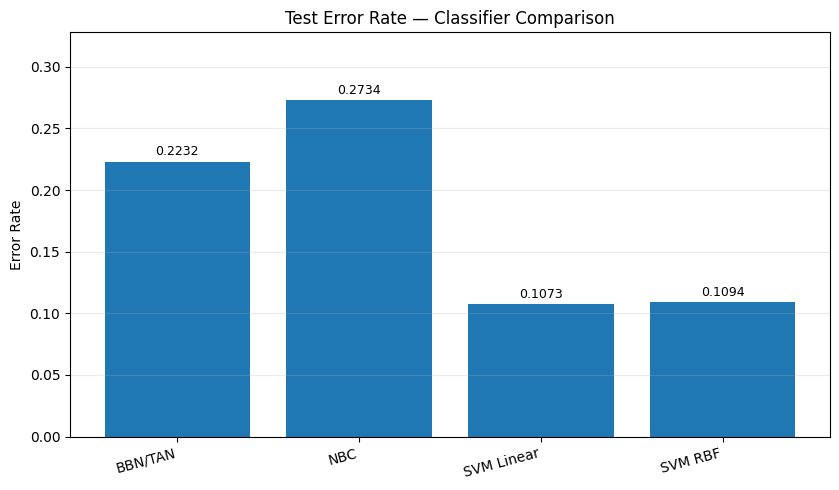

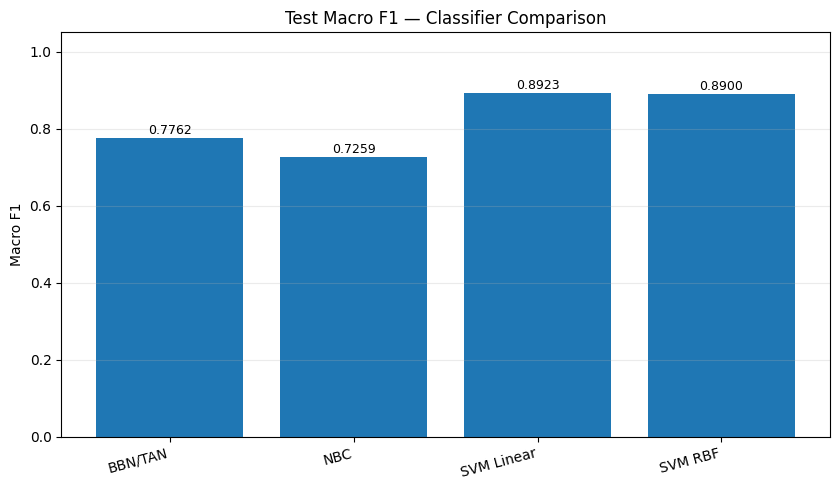

In [10]:
plot_df = comparison_df.copy()

fig, ax = plt.subplots(figsize=(8.5, 5))
ax.bar(plot_df["model"], plot_df["error_rate"])
ax.set_title("Test Error Rate — Classifier Comparison")
ax.set_ylabel("Error Rate")
ax.set_ylim(0, max(0.05, float(plot_df["error_rate"].max()) * 1.2))
ax.grid(axis="y", alpha=0.25)
for i, v in enumerate(plot_df["error_rate"]):
    ax.text(i, v + 0.005, f"{v:.4f}", ha="center", fontsize=9)
plt.xticks(rotation=15, ha="right")
fig.tight_layout()
fig.savefig(
    OUTPUT_DIR / "classifier_error_rate_comparison.png",
    dpi=180,
    bbox_inches="tight",
)
plt.show()


fig, ax = plt.subplots(figsize=(8.5, 5))
ax.bar(plot_df["model"], plot_df["macro_f1"])
ax.set_title("Test Macro F1 — Classifier Comparison")
ax.set_ylabel("Macro F1")
ax.set_ylim(0, 1.05)
ax.grid(axis="y", alpha=0.25)
for i, v in enumerate(plot_df["macro_f1"]):
    ax.text(i, v + 0.01, f"{v:.4f}", ha="center", fontsize=9)
plt.xticks(rotation=15, ha="right")
fig.tight_layout()
fig.savefig(
    OUTPUT_DIR / "classifier_macro_f1_comparison.png",
    dpi=180,
    bbox_inches="tight",
)
plt.show()


## ۱۱. خلاصه پارامترها و ذخیره خروجی نهایی

تمام جدول‌ها، ماتریس‌های درهم‌ریختگی، گزارش‌های کلاسی و نمودارها در مسیر زیر ذخیره می‌شوند:

`outputs/svm_classification/`

در Google Colab، در پایان یک فایل ZIP از خروجی‌ها ساخته می‌شود.

In [11]:
summary = {
    "task": "dataset_source_classification",
    "class_mapping": {
        "0": "CommonsenseQA",
        "1": "ARC-Challenge",
    },
    "features": FEATURES,
    "excluded_feature": "option_count",
    "split_counts": {
        split_name: {
            CLASS_NAMES[class_id]: int(count)
            for class_id, count in part["y"].value_counts().items()
        }
        for split_name, part in [
            ("train", train_df),
            ("validation", val_df),
            ("test", test_df),
        ]
    },
    "scaling": "StandardScaler fitted on training data only; final fit on train+validation",
    "class_weight": "balanced",
    "validation_selection_metric": "macro_f1; tie-breakers: balanced_accuracy, accuracy",
    "svm_linear": {
        "C": BEST_LINEAR_C,
        "test_metrics": {
            key: float(value)
            for key, value in linear_test_metrics.items()
        },
    },
    "svm_rbf": {
        "C": BEST_RBF_C,
        "gamma": BEST_RBF_GAMMA,
        "test_metrics": {
            key: float(value)
            for key, value in rbf_test_metrics.items()
        },
    },
    "previous_baselines_included": bool(same_test_counts),
    "previous_baselines_source": "classification_v3.zip from the previous Notebook 04 run",
    "note": (
        "This experiment classifies dataset source (CommonsenseQA vs ARC-Challenge). "
        "It does not directly measure LLM correctness, uncertainty estimation, "
        "or silent failures."
    ),
}

with open(
    OUTPUT_DIR / "svm_experiment_summary.json",
    "w",
    encoding="utf-8",
) as file:
    json.dump(summary, file, ensure_ascii=False, indent=2)

print("خروجی‌ها در مسیر زیر ذخیره شدند:")
print(OUTPUT_DIR)

print("\nپارامترهای نهایی:")
print("SVM Linear C:", BEST_LINEAR_C)
print("SVM RBF C:", BEST_RBF_C)
print("SVM RBF gamma:", BEST_RBF_GAMMA)

import shutil
local_zip = Path(PROJECT_ROOT) / "outputs" / "svm_classification.zip"
shutil.make_archive(
    str(local_zip.with_suffix("")),
    "zip",
    OUTPUT_DIR,
)
print("\nفایل فشرده خروجی‌ها ایجاد شد:")
print(local_zip)

if IN_COLAB:
    zip_path = Path("/content/svm_classification_results.zip")
    shutil.make_archive(
        str(zip_path.with_suffix("")),
        "zip",
        OUTPUT_DIR,
    )
    print("\nفایل ZIP برای دانلود در Colab ساخته شد:")
    print(zip_path)


خروجی‌ها در مسیر زیر ذخیره شدند:
D:\app\ai\Detecting Silent Failures of Uncertainty Estimators\outputs\svm_classification

پارامترهای نهایی:
SVM Linear C: 0.01
SVM RBF C: 10.0
SVM RBF gamma: 1

فایل فشرده خروجی‌ها ایجاد شد:
D:\app\ai\Detecting Silent Failures of Uncertainty Estimators\outputs\svm_classification.zip


## ۱۲. راهنمای تفسیر نتایج

هنگام نوشتن گزارش، این موارد را رعایت کن:

1. مدل خطی و مدل RBF را فقط بر اساس Test مقایسه کن؛ انتخاب پارامترها باید بر اساس Validation باشد.
2. `Error Rate` برابر `1 - Accuracy` است.
3. `Class Error` برابر `1 - Recall` همان کلاس است.
4. اگر RBF بهتر از Linear باشد، فقط می‌توان گفت در این ویژگی‌ها و این تقسیم‌بندی، مرز غیرخطی عملکرد بهتری داشته است؛ این نتیجه به‌تنهایی اثبات‌کننده ساختار غیرخطی قطعی در کل داده‌ها نیست.
5. نتیجه NBC و BBN/TAN از اجرای قبلی نوت‌بوک ۰۴ وارد جدول می‌شود. اگر داده یا splitها عوض شده باشند، برای مقایسه منصفانه باید نوت‌بوک ۰۴ نیز با همان نسخه داده دوباره اجرا شود.
6. این آزمایش همچنان طبقه‌بندی منبع دیتاست است و نباید به‌عنوان نتیجه تشخیص Silent Failure در مقاله اصلی معرفی شود.